### **Imports**

In [ ]:
%load_ext autoreload
%autoreload 2
%cd ..

import warnings
warnings.filterwarnings("ignore")

import torch
import numpy as np
from pathlib import Path
from huggingface_hub import hf_hub_download
from src.config import REPO_ID, HF_TOKEN, EXTRACTED_DATA_DIR
from src.processing.yolo import load_eval_model, find_sppf_layer, run_false_positive_inference
from src.utils.visualization import plot_false_positive_inline
from src.processing.yolo import run_dataset_predictions_db, evaluate_predictions
from src.utils.visualization import plot_unified_calibration_curves
from ultralytics import YOLO

### **EigenCAM Visualization**

Running Inference on Negatives: 100%|██████████| 810/810 [07:43<00:00,  1.75it/s]



Generating EigenCAM maps for top-10 hardest False Positives...


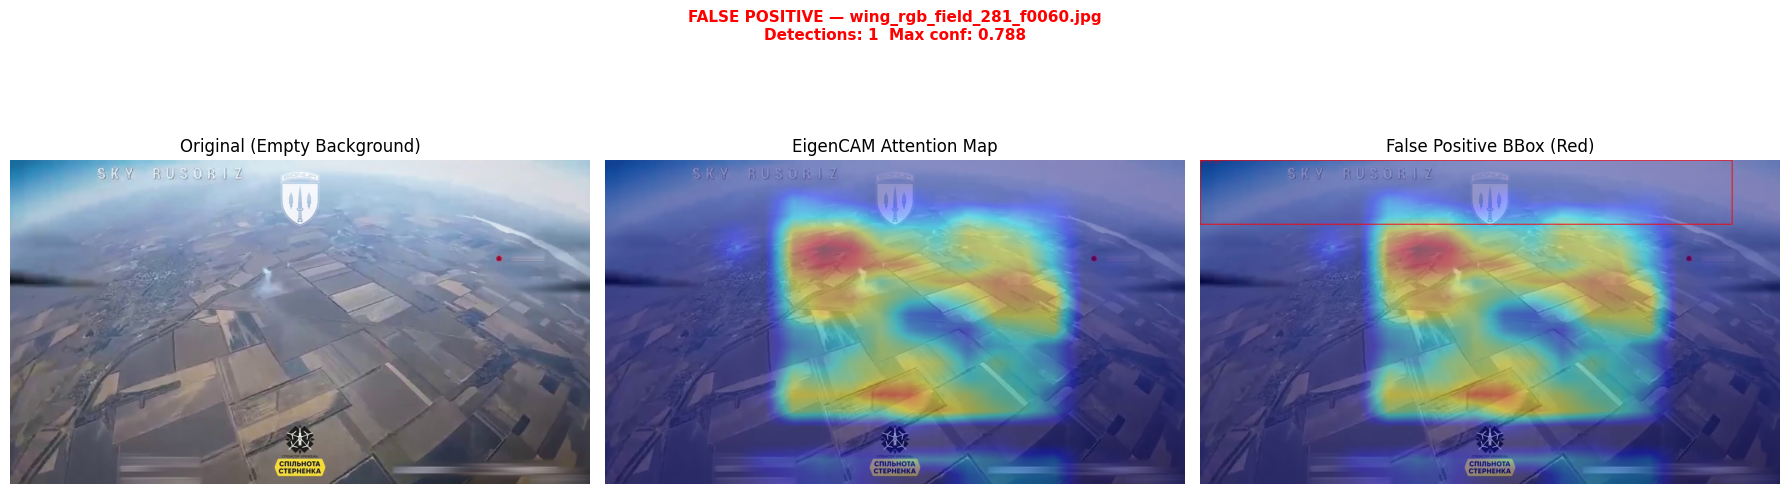

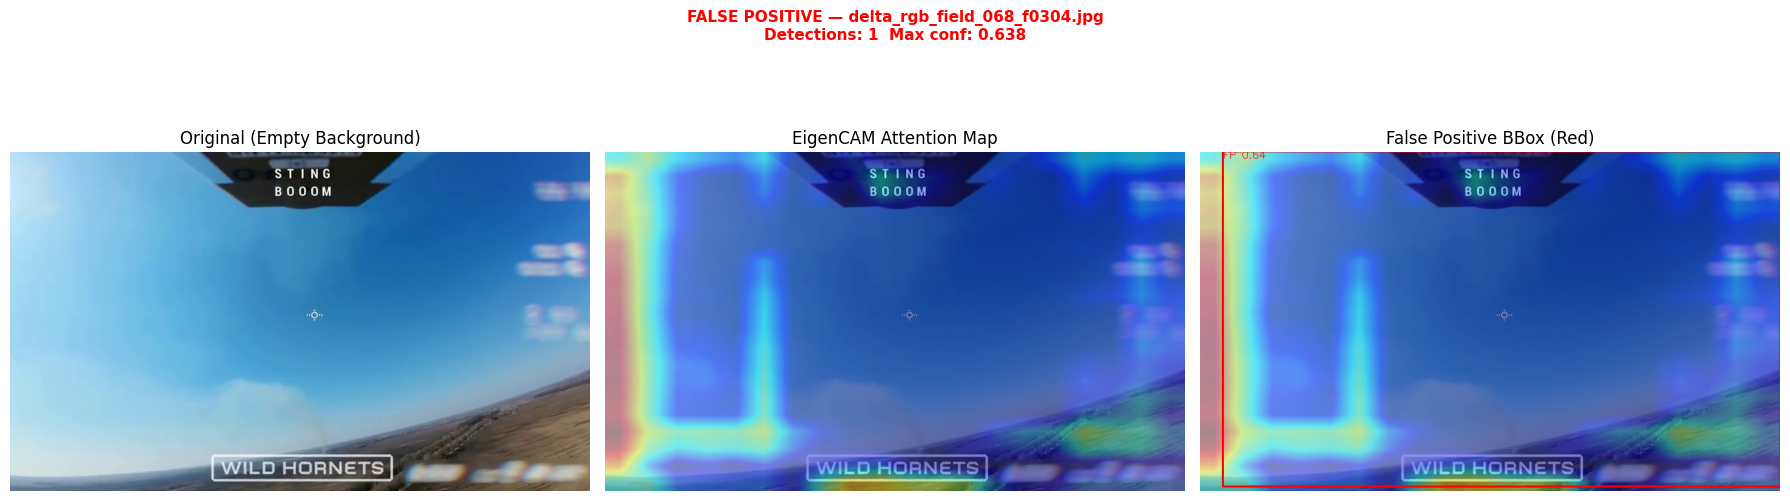

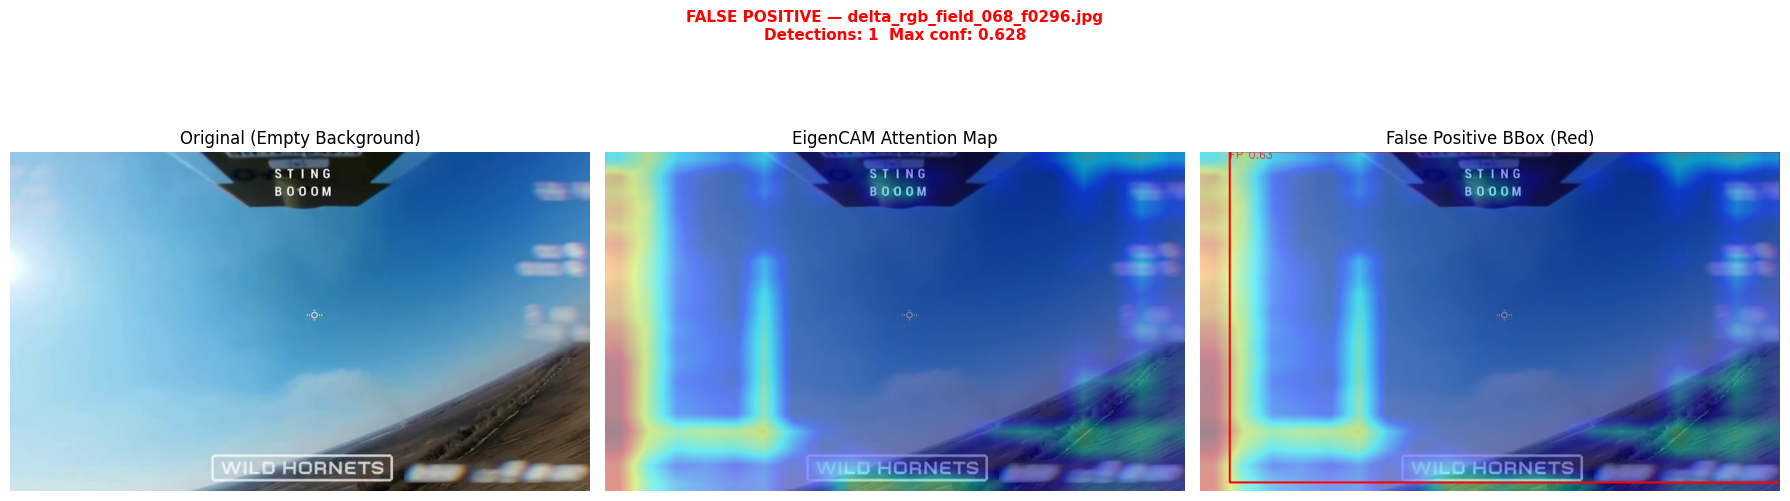

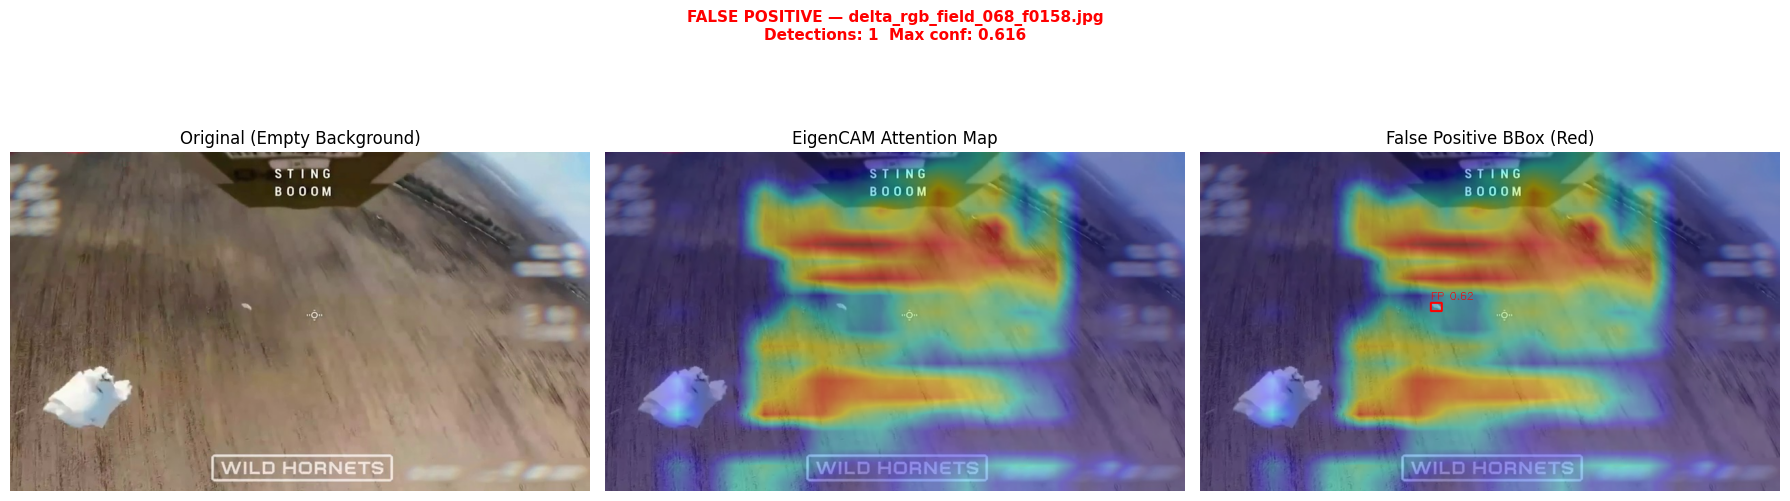

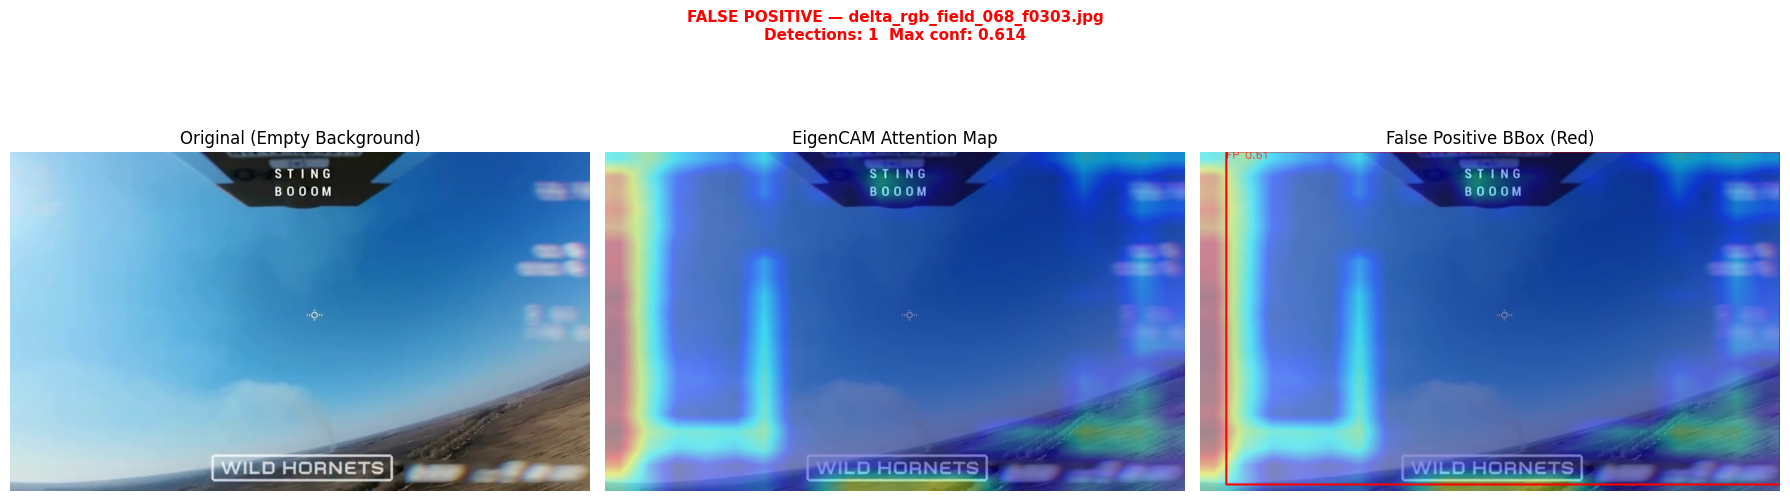

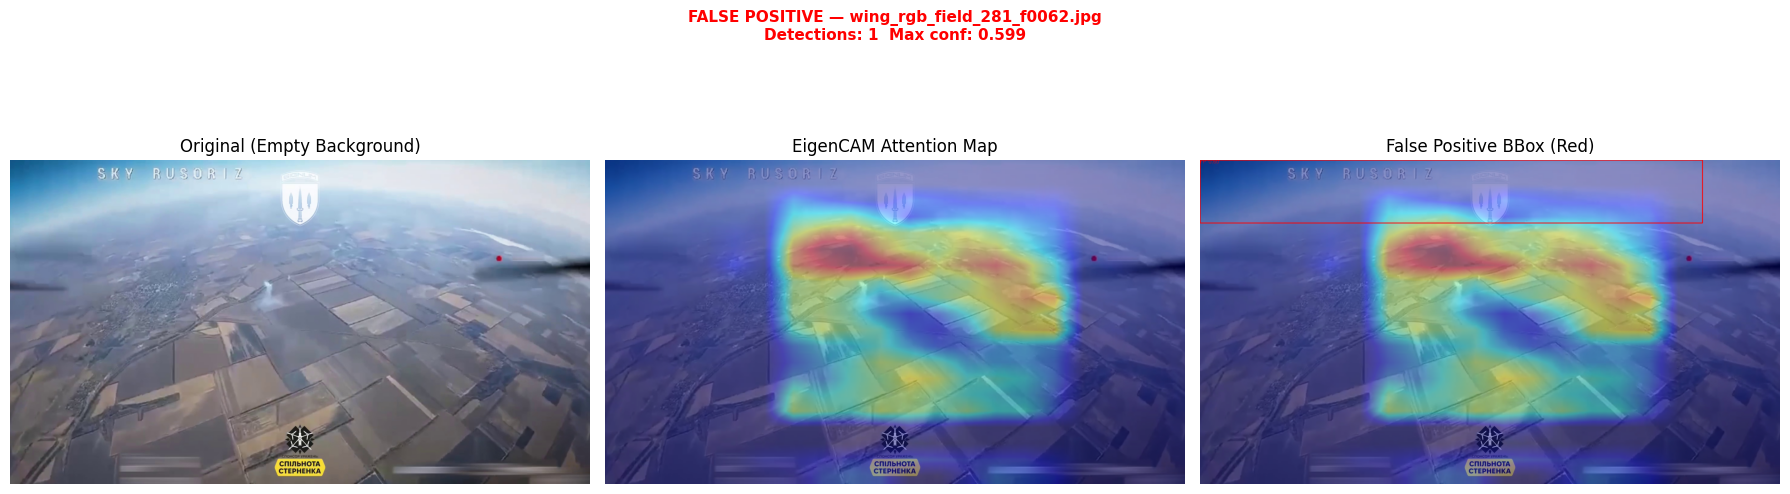

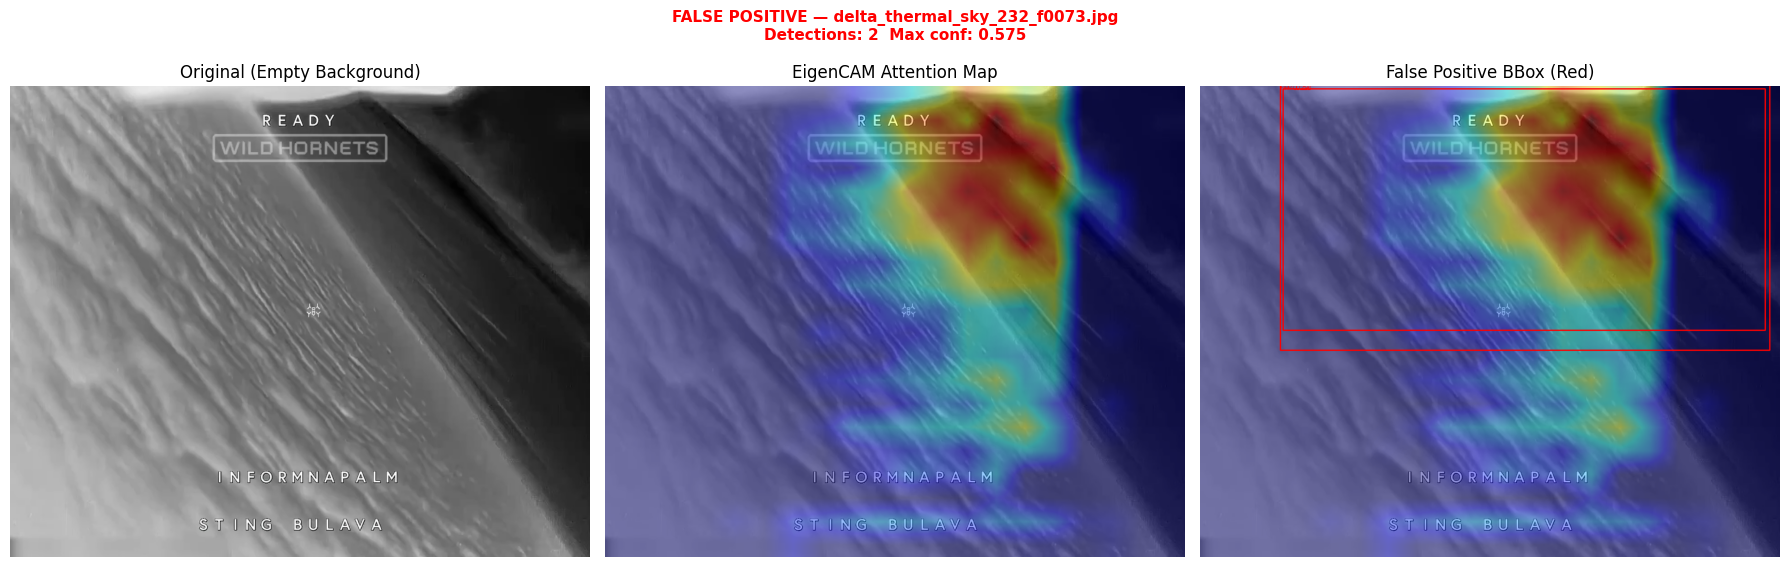

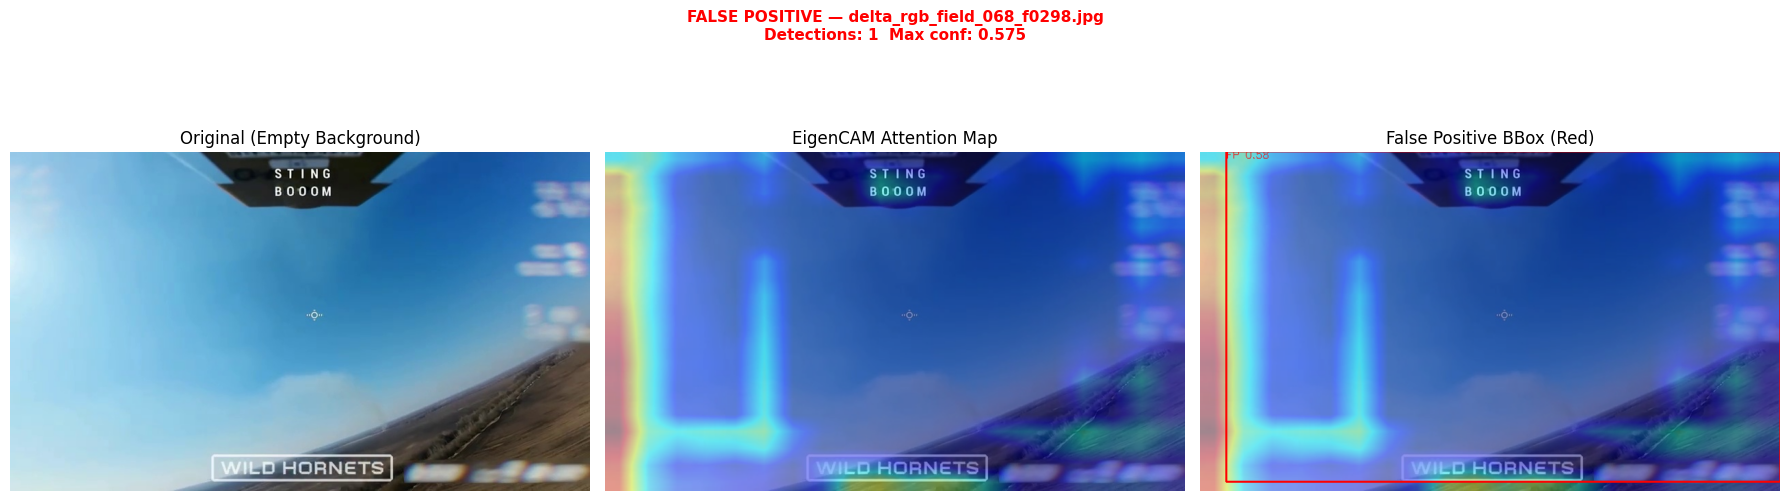

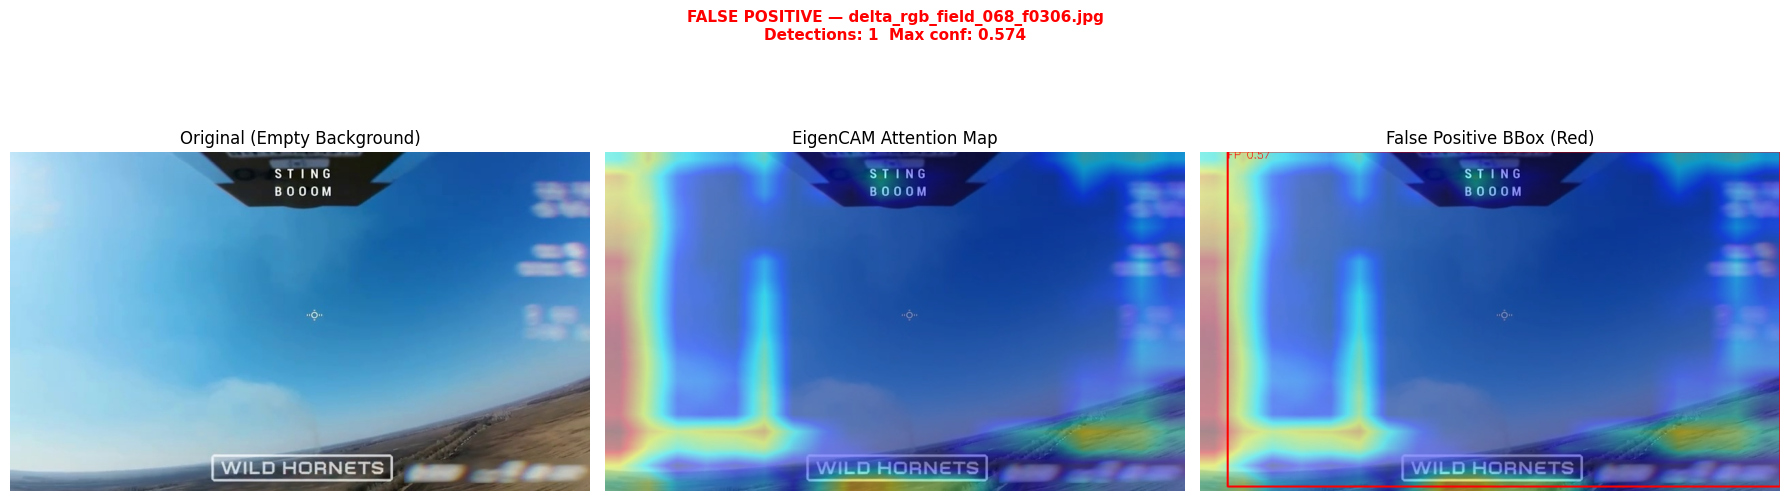

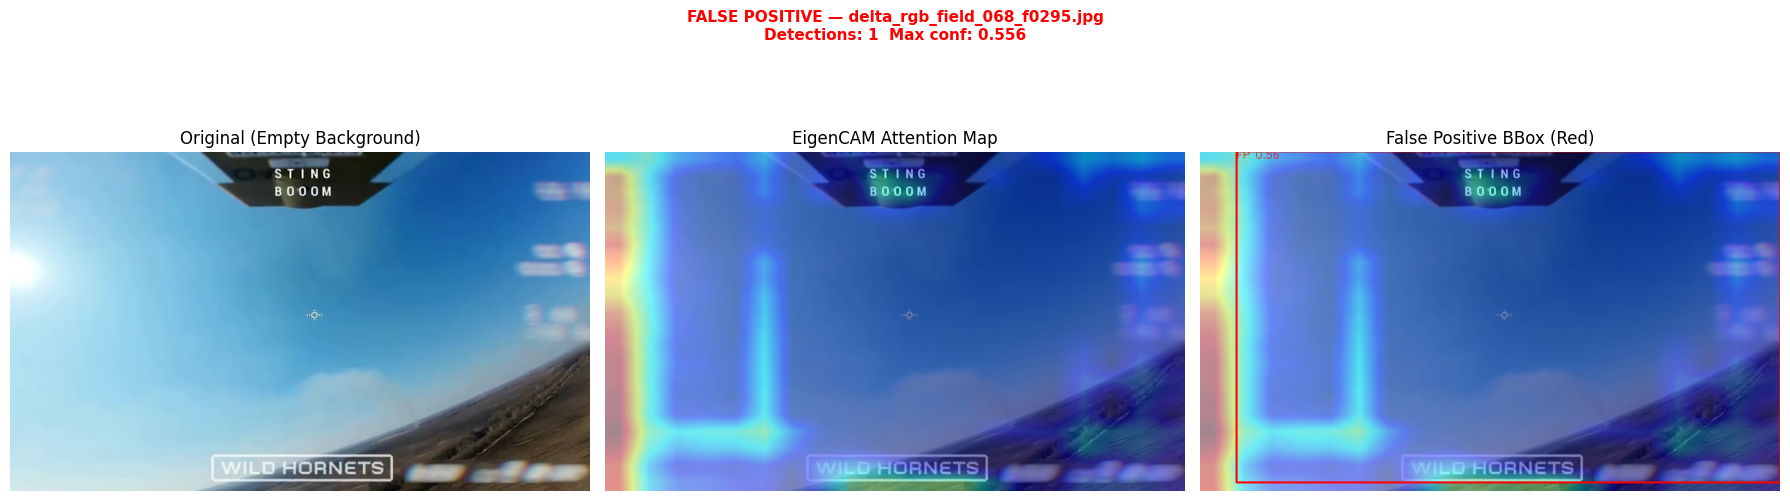


FALSE POSITIVE MINING REPORT
Total Negatives Verified : 810
False Positives Found    : 25
False Positive Rate      : 3.09%


In [ ]:
MODEL_FILE = "models/yolo26n_run_with_negatives_best.pt"
NEGATIVES_DIR = EXTRACTED_DATA_DIR / "train" / "RAW_NEGATIVES"

weights_path = hf_hub_download(
    repo_id=REPO_ID,
    filename=MODEL_FILE,
    token=HF_TOKEN,
    repo_type="dataset",
    local_dir="hf_weights"
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model, pytorch_model = load_eval_model(str(weights_path), device)
target_layer, _ = find_sppf_layer(pytorch_model)

false_positives = run_false_positive_inference(model, NEGATIVES_DIR, conf_thresh=0.25)

if not false_positives:
    print("\n✅ Zero False Positives found! The model handles negative frames correctly.")
else:
    TOP_N = 10
    top_fps = false_positives[:TOP_N]
    print(f"\nGenerating EigenCAM maps for top-{len(top_fps)} hardest False Positives...")
    
    for fp in top_fps:
        plot_false_positive_inline(fp, pytorch_model, target_layer, device)
        
    total_negatives = len(list(NEGATIVES_DIR.glob("*.jpg")))
    print("\n" + "="*50)
    print("FALSE POSITIVE MINING REPORT")
    print("="*50)
    print(f"Total Negatives Verified : {total_negatives}")
    print(f"False Positives Found    : {len(false_positives)}")
    print(f"False Positive Rate      : {len(false_positives)/total_negatives*100:.2f}%")
    print("="*50)

### **Threshold Calibration**

In [ ]:
weights_path = Path(hf_hub_download(
    repo_id=REPO_ID, filename="models/yolo26n_final_model_best.pt", repo_type="dataset", token=HF_TOKEN
))

model = YOLO(str(weights_path))
test_dir = EXTRACTED_DATA_DIR / "test"

raw_database = run_dataset_predictions_db(model, test_dir, imgsz=1280)

Running Evaluation Inference: 100%|██████████| 2524/2524 [16:31<00:00,  2.55it/s] 


             UNIFIED METRICS CALIBRATION REPORT             
Optimal Threshold (Max F0.5 - Homing focus): 0.7250
  Precision at F0.5 Threshold              : 0.9692
  Recall at F0.5 Threshold                 : 0.7304
  Maximized F0.5-Score                     : 0.9097
  False Alarm Rate on Negatives            : 1.23%
------------------------------------------------------------
Optimal Threshold (Max F1 - Standard balanced): 0.2750
  Precision at F1 Threshold                : 0.8904
  Recall at F1 Threshold                   : 0.8264
  Maximized F1-Score                       : 0.8572
  False Alarm Rate on Negatives            : 3.29%


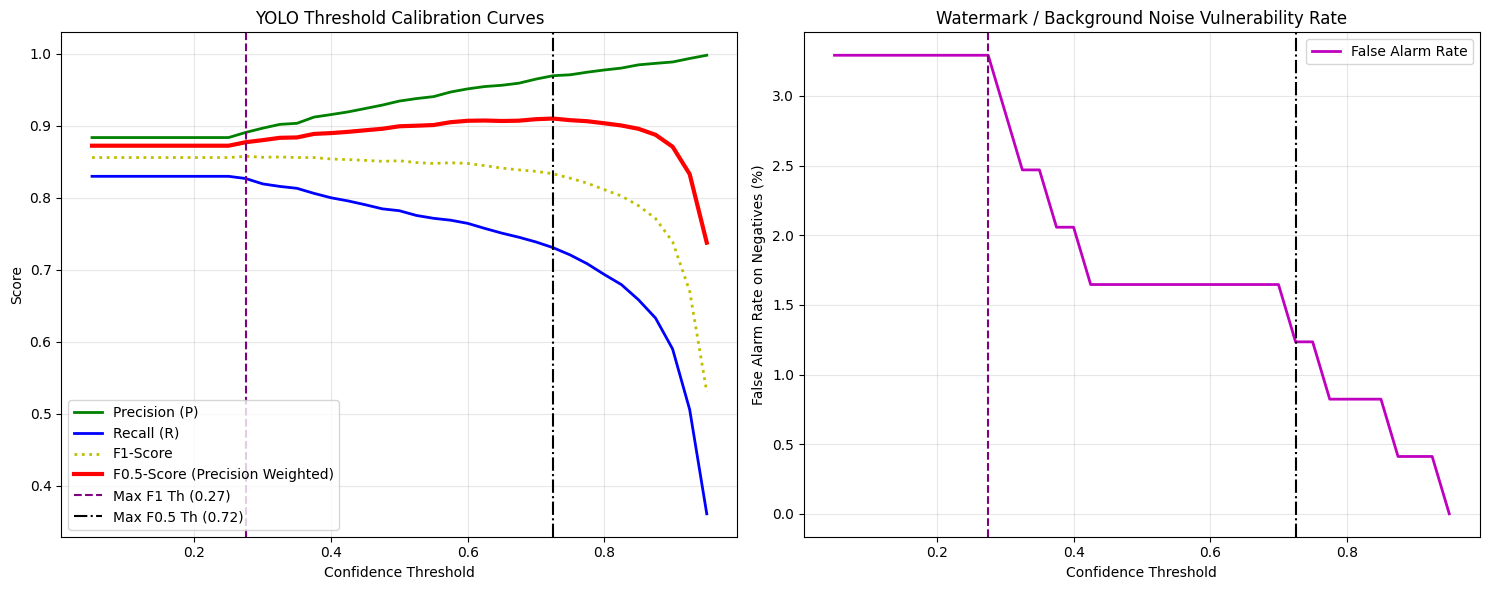

In [5]:
thresholds = np.linspace(0.05, 0.95, 37)
precision_curve, recall_curve, f1_curve, f05_curve, neg_fa_rate = [], [], [], [], []

for t in thresholds:
    tps_count, fps_count, fns_count = 0, 0, 0
    total_negatives, negatives_with_false_alarms = 0, 0
    
    for entry in raw_database:
        filtered_preds = [p for p in entry["pred_boxes"] if p[4] >= t]
        tp, fp, fn = evaluate_predictions(entry["gt_boxes"], filtered_preds)
        
        tps_count += len(tp)
        fps_count += len(fp)
        fns_count += len(fn)
        
        if not entry["is_positive"]:
            total_negatives += 1
            if len(filtered_preds) > 0:
                negatives_with_false_alarms += 1
        
    p = tps_count / (tps_count + fps_count) if (tps_count + fps_count) > 0 else 1.0
    r = tps_count / (tps_count + fns_count) if (tps_count + fns_count) > 0 else 0.0
    
    f1 = 2 * (p * r) / (p + r) if (p + r) > 0 else 0.0
    f05 = 1.25 * (p * r) / (0.25 * p + r) if (0.25 * p + r) > 0 else 0.0
    fa_rate = (negatives_with_false_alarms / total_negatives * 100) if total_negatives > 0 else 0.0
    
    precision_curve.append(p)
    recall_curve.append(r)
    f1_curve.append(f1)
    f05_curve.append(f05)
    neg_fa_rate.append(fa_rate)

opt_f05_idx = np.argmax(f05_curve)
opt_f1_idx = np.argmax(f1_curve)

opt_threshold_f05 = thresholds[opt_f05_idx]
opt_threshold_f1 = thresholds[opt_f1_idx]

print("="*60)
print("             UNIFIED METRICS CALIBRATION REPORT             ")
print("="*60)
print(f"Optimal Threshold (Max F0.5 - Homing focus): {opt_threshold_f05:.4f}")
print(f"  Precision at F0.5 Threshold              : {precision_curve[opt_f05_idx]:.4f}")
print(f"  Recall at F0.5 Threshold                 : {recall_curve[opt_f05_idx]:.4f}")
print(f"  Maximized F0.5-Score                     : {f05_curve[opt_f05_idx]:.4f}")
print(f"  False Alarm Rate on Negatives            : {neg_fa_rate[opt_f05_idx]:.2f}%")
print("-" * 60)
print(f"Optimal Threshold (Max F1 - Standard balanced): {opt_threshold_f1:.4f}")
print(f"  Precision at F1 Threshold                : {precision_curve[opt_f1_idx]:.4f}")
print(f"  Recall at F1 Threshold                   : {recall_curve[opt_f1_idx]:.4f}")
print(f"  Maximized F1-Score                       : {f1_curve[opt_f1_idx]:.4f}")
print(f"  False Alarm Rate on Negatives            : {neg_fa_rate[opt_f1_idx]:.2f}%")
print("="*60)

plot_unified_calibration_curves(
    thresholds, precision_curve, recall_curve, f1_curve, f05_curve, neg_fa_rate,
    opt_threshold_f1, opt_threshold_f05
)